# Library

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import issparse
import seaborn as sns
import random
import torch
#from squidpy.

from pathlib import Path

In [ ]:
def set_full_reproducibility(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False



set_full_reproducibility(42)

In [ ]:
from joblib import load, dump

# Define Functions

In [ ]:
def aggregate_attention_matrix_optimized(attn_matrix, labels):
    """
    Versione Memory-Efficient: Invece di convertire l'intera matrice in DataFrame,
    usa numpy slicing per calcolare le medie per blocco.
    """
    # Assicurati che i labels siano stringhe o categorie
    labels = np.array(labels)
    unique_labels = np.unique(labels)
    # Ordina numericamente se possibile, altrimenti lessicalmente
    try:
        unique_labels = sorted(unique_labels, key=lambda x: int(x))
    except:
        unique_labels = sorted(unique_labels)
    
    n_labels = len(unique_labels)
    aggregated = np.zeros((n_labels, n_labels))
    
    # Pre-calcola gli indici per ogni label per evitare di farlo nel doppio loop
    label_indices = {label: np.where(labels == label)[0] for label in unique_labels}
    
    # Doppio loop sulle classi (molto più leggero per la RAM rispetto al groupby su NxN)
    for i, row_label in enumerate(unique_labels):
        row_idxs = label_indices[row_label]
        # Pre-slice delle righe per velocizzare
        row_data = attn_matrix[row_idxs, :]
        
        for j, col_label in enumerate(unique_labels):
            col_idxs = label_indices[col_label]
            # Slice delle colonne e calcolo media ignorando i NaN
            # Usa il blocco sliced, non l'intera matrice
            block = row_data[:, col_idxs]
            aggregated[i, j] = np.nanmean(block)
            
    return pd.DataFrame(aggregated, index=unique_labels, columns=unique_labels)


def aggregate_attention_matrices(matrices_dict):
    """
    Aggrega matrici di attenzione con potenziali differenze in indici/colonne.
    """
    if not matrices_dict:
        return None
    
    # Trova tutti gli indici e colonne unici
    all_indices = set()
    all_columns = set()
    
    for _, matrix in matrices_dict.items():
        all_indices.update(matrix.index)
        all_columns.update(matrix.columns)
    
    all_indices = sorted(list(all_indices), key=lambda x: int(x) if str(x).isdigit() else x)
    all_columns = sorted(list(all_columns), key=lambda x: int(x) if str(x).isdigit() else x)
    # Inizializza matrici
    sum_matrix = pd.DataFrame(0.0, index=all_indices, columns=all_columns)
    count_matrix = pd.DataFrame(0.0, index=all_indices, columns=all_columns)
    
    # Aggrega
    for _, matrix in matrices_dict.items():
        # Allinea (reindex è più veloce se fatto su dataframes piccoli LxL come qui)
        aligned = matrix.reindex(index=all_indices, columns=all_columns)
        valid_mask = aligned.notna()
        
        sum_matrix += aligned.fillna(0)
        count_matrix += valid_mask.astype(float)
    
    # Calcola media
    average_matrix = sum_matrix / count_matrix.replace(0, np.nan)
    average_matrix.fillna(0, inplace=True)
    return average_matrix

# Prepare Data

In [ ]:
Bact_labels=pd.read_csv('Data/Bact_labels.csv')

In [ ]:
spdata=load('Data/NBDATA.h5ad')

In [ ]:
from scipy.sparse import csr_matrix
import scanpy as sc
import anndata
import scanpy.external as sce
# Integra i dataset
keys_to_integrate = ['Train_1', 'Train_2', 'Train_3','Train_5','Train_6']

adatas={}

for key in keys_to_integrate:
	dummy=spdata[key]['dataXNorm'].copy()
	dummy.layers['log1p_norm']=dummy.X.copy()
	dummy.obs['batch']=key
	sub_bact=Bact_labels[Bact_labels['Key']==key]
	sub_bact.index=sub_bact['spotID'].tolist()
	dummy.obs['bacteria']=sub_bact.loc[dummy.obs.index,'Prediction'].values
	old_key=next(iter(dummy.uns['spatial']))
	value=dummy.uns['spatial'].pop(old_key)
	dummy.uns['spatial'][key]=value
	dummy.var_names_make_unique()
	adatas[key]=dummy

In [ ]:
adata_all = anndata.concat(
    adatas.values(),
    join='inner',          
    merge='same',
    uns_merge='unique',     
    index_unique='_'     
)

In [ ]:
adata=adata_all
adata
adata.obs['condition']=adata.obs['batch'].apply(lambda x: 'Infected' if x in ['Train_1','Train_2','Train_3'] else 'Control')

adata.obs['condition'].value_counts()

condition
Infected    9913
Control     5179
Name: count, dtype: int64

## 1. Norm

In [ ]:
print(f'Min count: {adata.X.min()}, Max count: {adata.X.max()}')

Min count: 0.0, Max count: 8.53908634185791


In [ ]:
print(f'Min count: {adata.layers["log1p_norm"].min()}, Max count: {adata.layers["log1p_norm"].max()}')


Min count: 0.0, Max count: 8.367738723754883


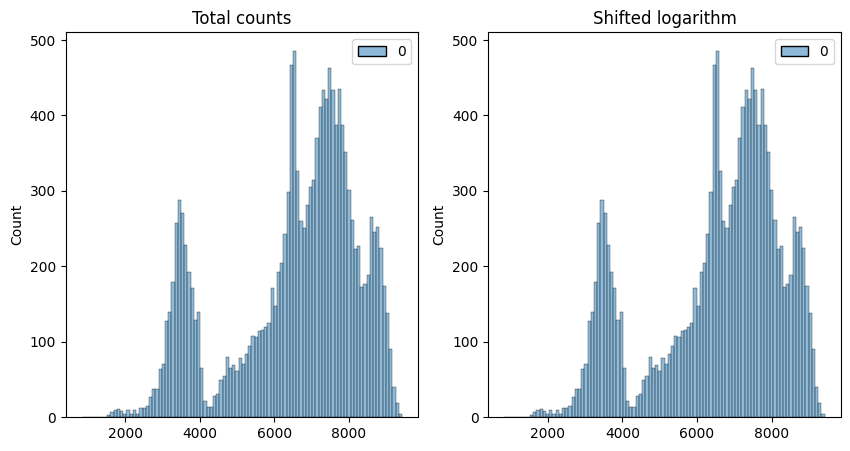

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(adata.X.sum(1), bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(adata.layers["log1p_norm"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Shifted logarithm")
plt.show()

## 2. Spatial Graph

In [ ]:
adata.obs['batch']=adata.obs['batch'].astype('category')

In [ ]:
sq.gr.spatial_neighbors(
    adata,
    coord_type = "grid",
	library_key = "batch"
)

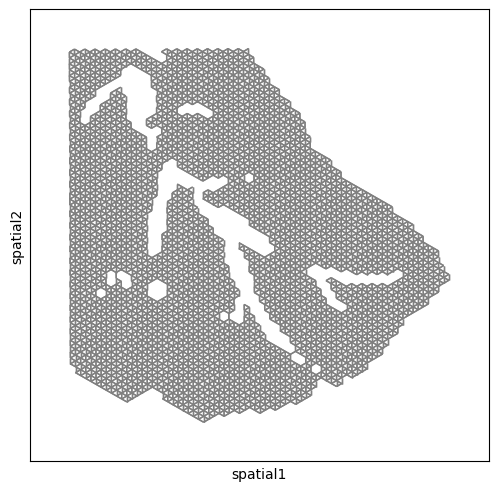

In [ ]:
sq.pl.spatial_scatter(
    adata,
    connectivity_key="spatial_connectivities",
    img=False,
	library_key='batch',
    library_id = 'Train_1'
)

## 3. Calculate sliding windows

In [ ]:
tissue_cell_number = adata.obs.groupby('batch').size()
print(f"Nr cells per sliding window: Min: {tissue_cell_number.min()}, Max: {tissue_cell_number.max()}, Avg: {tissue_cell_number.mean()}")

Nr cells per sliding window: Min: 2452, Max: 3384, Avg: 3018.4


/beegfs/scratch/tmp/ipykernel_2648756/3598221288.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tissue_cell_number = adata.obs.groupby('batch').size()


<Axes: xlabel='batch'>

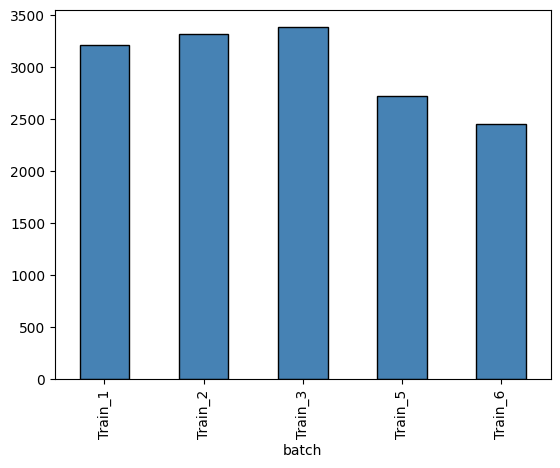

In [ ]:

tissue_cell_number.plot(kind='bar', color='steelblue', edgecolor='black')

In [ ]:
MAX_CELLS=2000

In [ ]:
batches_over_4k = tissue_cell_number[tissue_cell_number > MAX_CELLS]
print(batches_over_4k)

batch
Train_1    3212
Train_2    3317
Train_3    3384
Train_5    2727
Train_6    2452
dtype: int64


In [ ]:
sq.tl.sliding_window(
    adata=adata,
    library_key="batch",  # to stratify by sample
    window_size=3500,
    overlap=0,
    copy=False,  # we modify in place
)

In [ ]:
window_size = adata.obs.groupby('sliding_window_assignment').size()
print(f"Nr cells per sliding window: Min: {window_size.min()}, Max: {window_size.max()}, Avg: {window_size.mean()}")

Nr cells per sliding window: Min: 8, Max: 603, Avg: 343.0


/beegfs/scratch/tmp/ipykernel_2648756/3351268401.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  window_size = adata.obs.groupby('sliding_window_assignment').size()


/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/

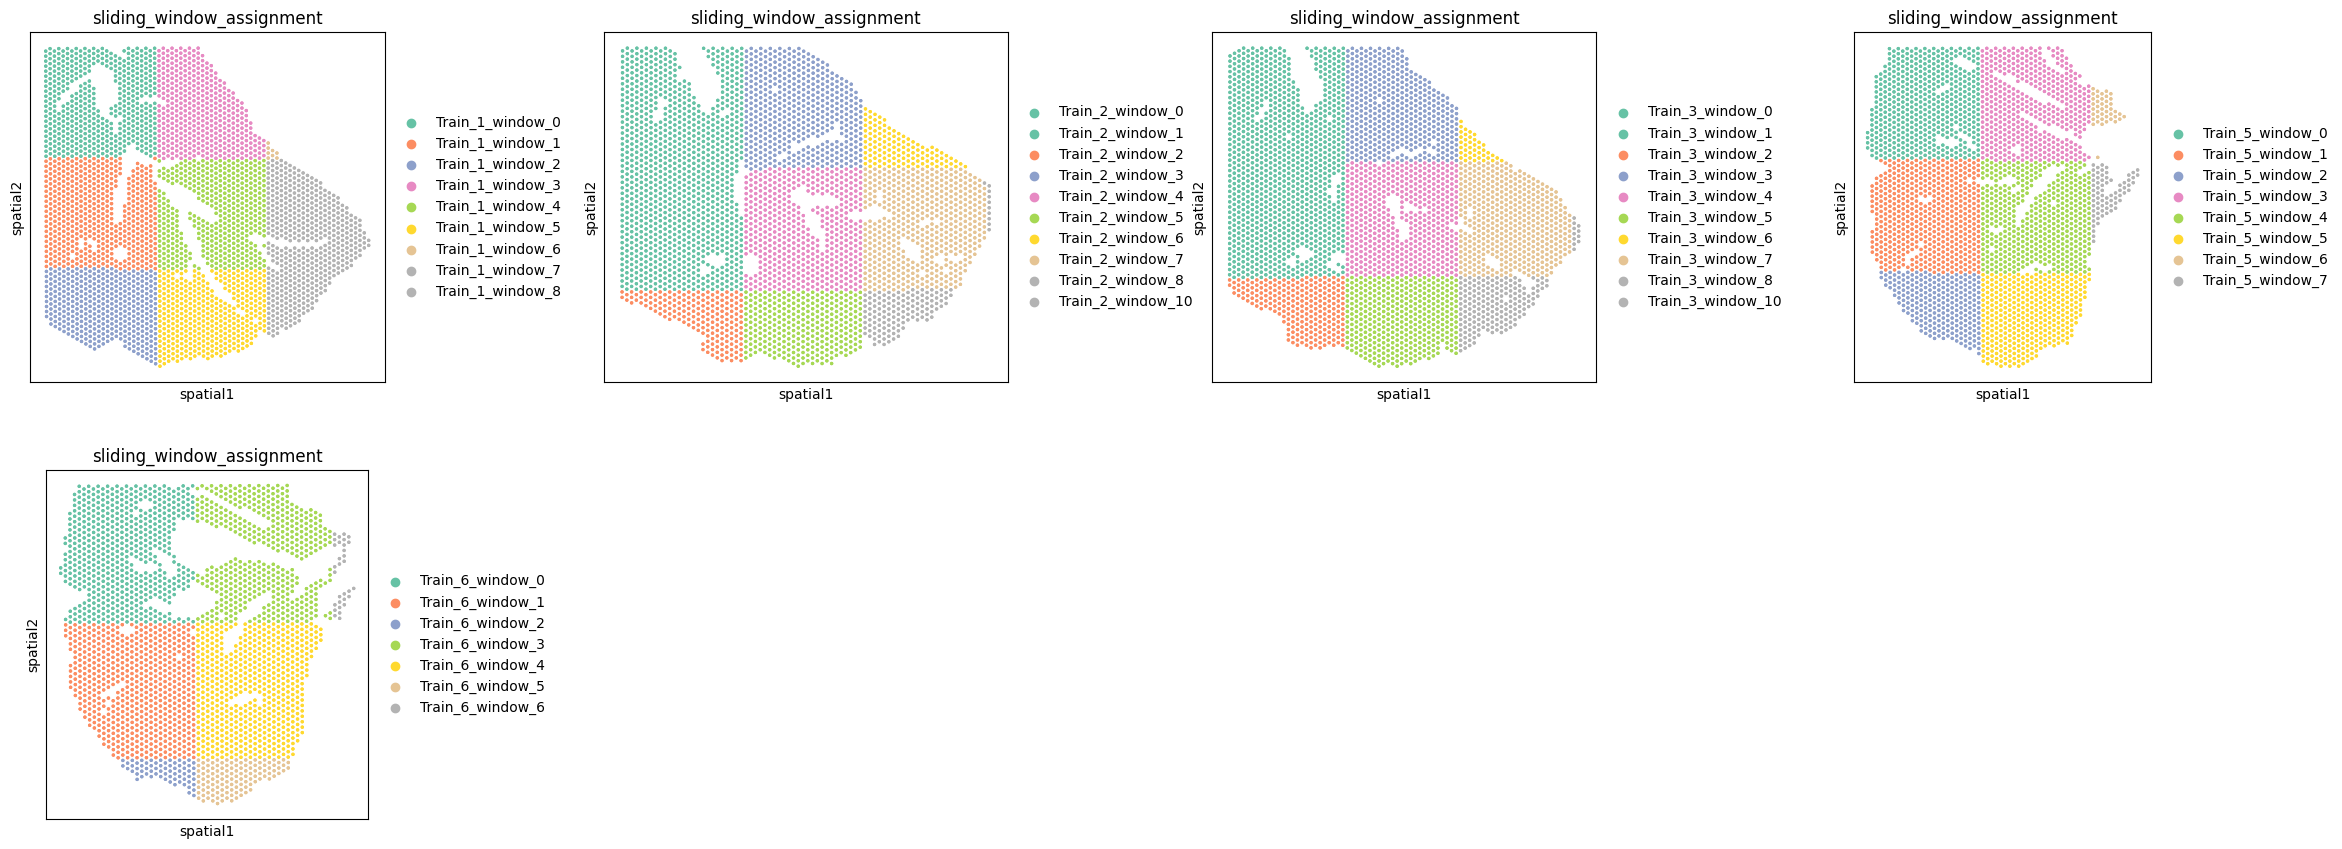

In [ ]:
sq.pl.spatial_scatter(adata, color='sliding_window_assignment', library_key = 'batch',shape=None,palette='Set2')

In [ ]:
## Create SPlit
proportions = {'train': 0.7, 'val': 0.2, 'test': 0.1}
splits = list(proportions.keys())
weights = list(proportions.values())

def stratified_split(group_df, splits, weights):
    """
    Assegna le etichette di split ('train', 'val', 'test') in modo casuale
    agli indici del sottogruppo in base ai pesi specificati (70/20/10).
    """
    n_rows = len(group_df)
    # Genera le etichette di split casuali in base ai pesi
    split_labels = np.random.choice(splits, size=n_rows, p=weights)
    
    # Restituisce una Serie con le etichette e gli indici del sottogruppo,
    # in modo che Pandas possa riallineare correttamente i dati nel DataFrame originale.
    return pd.Series(split_labels, index=group_df.index)


adata.obs['split'] = adata.obs.groupby('sliding_window_assignment', group_keys=False).apply(
    lambda x: stratified_split(x, splits, weights)
)

/beegfs/scratch/tmp/ipykernel_2648756/1299469500.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs['split'] = adata.obs.groupby('sliding_window_assignment', group_keys=False).apply(
/beegfs/scratch/tmp/ipykernel_2648756/1299469500.py:20: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  adata.obs['split'] = adata.obs.groupby('sliding_window_assignment', group_keys=False).apply(


In [ ]:
adata.write('Data/adata_bact.h5ad')

## 4. HVG

In [ ]:
adata.layers['counts']=adata.X.copy()

adata.X=adata.layers['log1p_norm'].copy()

In [ ]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000,subset=True)

In [ ]:
adata

AnnData object with n_obs × n_vars = 15092 × 2000
    obs: 'in_tissue', 'array_row', 'array_col', 'batch', 'bacteria', 'condition', 'sliding_window_assignment', 'globalX', 'globalY', 'split', '_scvi_batch', '_scvi_labels', 'cluster_cellcharter'
    var: 'gene_ids', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'dispersions', 'dispersions_norm'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'cluster_cellcharter_colors', 'log1p', 'sliding_window_assignment_colors', 'spatial', 'spatial_neighbors', 'type_colors', 'hvg'
    obsm: 'X_cellcharter', '_scvi_extra_categorical_covs', 'scvi_latent', 'spatial'
    layers: 'log1p_norm', 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [ ]:
adata.write('Data/adata_bact_hvg.h5ad')

## 5. Bacterial labels

In [ ]:
adata=sc.read_h5ad('INTERACTION/prove_interscale/adata_bact.h5ad')

In [ ]:
from sklearn.cluster import KMeans

pred=adata.obs['bacteria'].values


n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=0)
kmeans_labels = kmeans.fit_predict(pred.reshape(-1,1))

means = [pred[kmeans_labels == i].mean() if np.any(kmeans_labels == i) else -np.inf for i in range(n_clusters)]
order = np.argsort(means)
mapping = {old: new for new, old in enumerate(order)}
kmeans_labels_ordered = np.array([mapping[l] for l in kmeans_labels])



In [ ]:
adata.obs['bacterial_labels']=kmeans_labels_ordered


adata.obs['bacterial_labels']=adata.obs['bacterial_labels'].map({0:0,1:0,2:1})

adata.obs['bacterial_labels']=adata.obs['bacterial_labels'].astype('category')

# Run Local(Modular) + Global(Transformer)

In [ ]:
import interscale as interscale
from interscale.tl import prepare_geome_dataset
from interscale.geome_dataloader import GraphAnnDataModule
from interscale.config import load_config
from interscale.tl import remove_zero_expression_cells

import argparse
import scanpy as sc

/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assign

In [ ]:
cfg_path = 'configs/InterScale_Bact_Nrec_Modular.yaml'
model_type = 'CombinedModel'

In [ ]:
cfg = load_config(Path(cfg_path))
print(cfg)
adata = sc.read_h5ad(cfg.dataset.h5ad_data)

In [ ]:
adata

AnnData object with n_obs × n_vars = 15092 × 2000
    obs: 'in_tissue', 'array_row', 'array_col', 'batch', 'bacteria', 'condition', 'sliding_window_assignment', 'globalX', 'globalY', 'split', '_scvi_batch', '_scvi_labels', 'cluster_cellcharter', 'bacterial_labels'
    var: 'gene_ids', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'dispersions', 'dispersions_norm'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'cluster_cellcharter_colors', 'hvg', 'log1p', 'sliding_window_assignment_colors', 'spatial', 'spatial_neighbors', 'type_colors'
    obsm: 'X_cellcharter', '_scvi_extra_categorical_covs', 'scvi_latent', 'spatial'
    layers: 'counts', 'log1p_norm'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [ ]:
cfg = load_config(cfg_path)
print(cfg)
adata = sc.read_h5ad(cfg.dataset.h5ad_data)
adata = remove_zero_expression_cells(adata)
interscale.model.CombinedModel._setup_anndata(adata = adata, prediction_task = cfg.dataset.prediction_task, layer_key = cfg.dataset.layer_key, sample_key_list = cfg.dataset.sample_key, prediction_obs = cfg.dataset.prediction_obs, group_key = cfg.dataset.group_label)

dataset:
  batch_size: 32
  description: 
  group_label: condition
  h5ad_data: /beegfs/scratch/ric.cirillo/dimarco.federico/PHD_gnn/INTERACTION/prove_interscale/adata_bact_hvg.h5ad
  layer_key: log1p_norm
  name: bactnrec
  num_classes: -1
  num_features: -1
  pct_mask_nodes: 0.3
  prediction_level: node
  prediction_obs: None
  prediction_task: regression
  sample_key: ['sliding_window_assignment']
  segmentation_robustness: [0.2, 0.5]
  spatial_neigbors_kwargs:
    coord_type: generic
    library_key: sample
    n_neighs: 6
    radius: 200
  split_key: split
  stratify_group: None
  test_size: 0.1
  train_size: 0.7
  val_size: 0.2
model:
  decoder:
    dropout_decoder: 0.1
    dual_decoder: True
    hidden_dims: [256, 128]
    type: linear
  global_component:
    latent_obsm_key: None
    name: self-attn-transformer
    parameters:
      activation_func: relu
      dim_feedforward: 256
      dropout_global: 0.1
      long_range_attention: False
      max_seq_len: 603
      n_heads: 

/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/scvi/data/fields/_base_field.py:63: UserWarning: adata.layers[log1p_norm] does not contain unnormalized count data. Are you sure this is what you want?
  self.validate_field(adata)


Anndata setup with scvi-tools version 1.4.0.post1.

     Summary Statistics     
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Summary Stat Key ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│  n_group_label   │   2   │
│  n_sample_key_0  │  44   │
│       n_x        │ 2000  │
└──────────────────┴───────┘

                  Data Registry                   
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃       scvi-tools Location       ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ group_label  │ adata.obs['_scvi_group_label']  │
│ sample_key_0 │ adata.obs['_scvi_sample_key_0'] │
│      x       │   adata.layers['log1p_norm']    │
└──────────────┴─────────────────────────────────┘

                            sample_key_0 State Registry                             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃            Source Location             ┃    Categories     ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['sliding_window_assignment'] │ Train_1_window_0  │          0          │
│                                        │ Train_2_window_0  │          1          │
│                                        │ Train_3_window_0  │          2          │
│                                        │ Train_5_window_0  │          3          │
│                                        │ Train_6_window_0  │          4          │
│                                        │ Train_1_window_1  │          5          │
│                                        │ Train_2_window_1  │          6          │
│                                        │ Train_3_window_1  │          7          │
│                                        │ Train_5_window_1  │          8          │
│                                        │ Train_6_window_1  │          9          │
│                                        │ Train_1_window_2  │         10          │
│                                        │ Train_2_window_2  │         11          │
│                                        │ Train_3_window_2  │         12          │
│                                        │ Train_5_window_2  │         13          │
│                                        │ Train_6_window_2  │         14          │
│                                        │ Train_1_window_3  │         15          │
│                                        │ Train_2_window_3  │         16          │
│                                        │ Train_3_window_3  │         17          │
│                                        │ Train_5_window_3  │         18          │
│                                        │ Train_6_window_3  │         19          │
│                                        │ Train_1_window_4  │         20          │
│                                        │ Train_2_window_4  │         21          │
│                                        │ Train_3_window_4  │         22          │
│                                        │ Train_5_window_4  │         23          │
│                                        │ Train_6_window_4  │         24          │
│                                        │ Train_1_window_5  │         25          │
│                                        │ Train_2_window_5  │         26          │
│                                        │ Train_3_window_5  │         27          │
│                                        │ Train_5_window_5  │         28          │
│                                        │ Train_6_window_5  │         29          │
│                                        │ Train_1_window_6  │         30          │
│                                        │ Train_2_window_6  │         31          │
│                                        │ Train_3_window_6  │         32          │
│                                        │ Train_5_window_6  │         33          │
│                                        │ Train_6_window_6  │         34          │
│                                        │ Train_1_window_7  │         35          │
│                                        │ Train_2_window_7  │         36          │
│                                        │ Train_3_window_7  │         37          │
│                                        │ Train_5_window_7  │         38          │
│                                        │ Train_1_window_8  │         39          │
│                                        │ Train_2_window_8  │         40          │
│                                        │ Train_3_window_8  │         41          │
│                                        │ Train_2_window_10 │         42          │
│    

                 group_label State Registry                  
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃    Source Location     ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['condition'] │  Control   │          0          │
│                        │  Infected  │          1          │
└────────────────────────┴────────────┴─────────────────────┘

In [ ]:

model = interscale.model.CombinedModel(
	adata,
	cfg = cfg
)

/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/torch/nn/modules/transformer.py:282: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


In [ ]:
adata.obsp['adjacency_matrix_connectivities']=adata.obsp['spatial_connectivities']

In [ ]:
pyg_data_list, _ = prepare_geome_dataset(adata, cfg)


dm = GraphAnnDataModule(datas=pyg_data_list, 
						num_workers=10,
						batch_size=int(cfg.dataset.batch_size), 
						pct_mask_nodes=cfg.dataset.pct_mask_nodes,
						learning_type="node")


Split key split already exists in adata.obs


In [ ]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [ ]:

model = interscale.model.CombinedModel(
	adata,
	cfg = cfg
)


model.train(max_epochs = 100, 
           datamodule = dm,
           early_stopping = True,
		   enable_progress_bar=True,
           wandb_use = False)

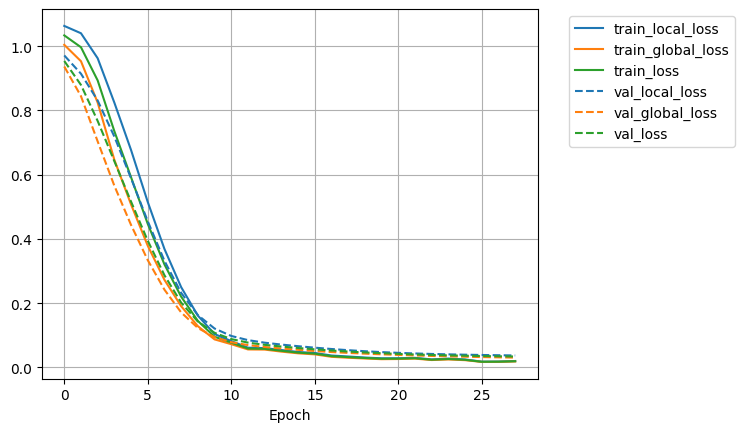

In [ ]:
model.history_.plot_history(subset_term = 'loss')



## Evaluate

In [ ]:
import interscale as interscale
from interscale.tl import prepare_geome_dataset
from interscale.geome_dataloader import GraphAnnDataModule
from interscale.config import load_config
from interscale.tl import remove_zero_expression_cells
from interscale.evaluation import scale_cls_by_sample
import argparse
import scanpy as sc

/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assign

In [ ]:
cfg_path = 'configs/InterScale_Bact_Nrec_Modular.yaml'
model_type = 'CombinedModel'
cfg = load_config(Path(cfg_path))
adata = sc.read_h5ad(cfg.dataset.h5ad_data)
adata = remove_zero_expression_cells(adata)

Nr. of zero expression cells: 0


In [ ]:
interscale.model.CombinedModel._setup_anndata(adata = adata, prediction_task = cfg.dataset.prediction_task, layer_key = cfg.dataset.layer_key, sample_key_list = cfg.dataset.sample_key, prediction_obs = cfg.dataset.prediction_obs)


/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/scvi/data/fields/_base_field.py:63: UserWarning: adata.layers[log1p_norm] does not contain unnormalized count data. Are you sure this is what you want?
  self.validate_field(adata)


Anndata setup with scvi-tools version 1.4.0.post1.

     Summary Statistics     
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Summary Stat Key ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│  n_sample_key_0  │  44   │
│   n_split_key    │   3   │
│       n_x        │ 2000  │
└──────────────────┴───────┘

                  Data Registry                   
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃       scvi-tools Location       ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ sample_key_0 │ adata.obs['_scvi_sample_key_0'] │
│  split_key   │  adata.obs['_scvi_split_key']   │
│      x       │   adata.layers['log1p_norm']    │
└──────────────┴─────────────────────────────────┘

                            sample_key_0 State Registry                             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃            Source Location             ┃    Categories     ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['sliding_window_assignment'] │ Train_1_window_0  │          0          │
│                                        │ Train_2_window_0  │          1          │
│                                        │ Train_3_window_0  │          2          │
│                                        │ Train_5_window_0  │          3          │
│                                        │ Train_6_window_0  │          4          │
│                                        │ Train_1_window_1  │          5          │
│                                        │ Train_2_window_1  │          6          │
│                                        │ Train_3_window_1  │          7          │
│                                        │ Train_5_window_1  │          8          │
│                                        │ Train_6_window_1  │          9          │
│                                        │ Train_1_window_2  │         10          │
│                                        │ Train_2_window_2  │         11          │
│                                        │ Train_3_window_2  │         12          │
│                                        │ Train_5_window_2  │         13          │
│                                        │ Train_6_window_2  │         14          │
│                                        │ Train_1_window_3  │         15          │
│                                        │ Train_2_window_3  │         16          │
│                                        │ Train_3_window_3  │         17          │
│                                        │ Train_5_window_3  │         18          │
│                                        │ Train_6_window_3  │         19          │
│                                        │ Train_1_window_4  │         20          │
│                                        │ Train_2_window_4  │         21          │
│                                        │ Train_3_window_4  │         22          │
│                                        │ Train_5_window_4  │         23          │
│                                        │ Train_6_window_4  │         24          │
│                                        │ Train_1_window_5  │         25          │
│                                        │ Train_2_window_5  │         26          │
│                                        │ Train_3_window_5  │         27          │
│                                        │ Train_5_window_5  │         28          │
│                                        │ Train_6_window_5  │         29          │
│                                        │ Train_1_window_6  │         30          │
│                                        │ Train_2_window_6  │         31          │
│                                        │ Train_3_window_6  │         32          │
│                                        │ Train_5_window_6  │         33          │
│                                        │ Train_6_window_6  │         34          │
│                                        │ Train_1_window_7  │         35          │
│                                        │ Train_2_window_7  │         36          │
│                                        │ Train_3_window_7  │         37          │
│                                        │ Train_5_window_7  │         38          │
│                                        │ Train_1_window_8  │         39          │
│                                        │ Train_2_window_8  │         40          │
│                                        │ Train_3_window_8  │         41          │
│                                        │ Train_2_window_10 │         42          │
│    

                split_key State Registry                 
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃  Source Location   ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['split'] │    test    │          0          │
│                    │   train    │          1          │
│                    │    val     │          2          │
└────────────────────┴────────────┴─────────────────────┘

In [ ]:
model=interscale.model.CombinedModel.load(adata=adata,cfg=cfg,dir_path='models',global_component=True, local_component=True)

/idle/ric.cirillo/dimarco.federico/envs/Interscale/lib/python3.11/site-packages/torch/nn/modules/transformer.py:282: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Loading model from /beegfs/scratch/ric.cirillo/dimarco.federico/PHD_gnn/INTERACTION/prove_interscale/model/dual_bactnrec_regr_node_44_GCN_self-attn-transformer_model.pt
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown


In [ ]:
set_full_reproducibility(42)
result = model.get_model_output(adata)

Load GEX from .layers/log1p_norm


## Clusters and Pathogens

In [ ]:
result_sub=result[result.obs['batch'].isin(['Train_1','Train_2','Train_3'])].copy()

In [ ]:
cl=pd.read_csv('Data/Integrated_Clusters.csv')

In [ ]:
cl['clusters']=cl['leiden'].map({0:'Parenchyma',1:'Inflammation',2:'Low_quality',3:'Airways',4:'SubMucosa'})

In [ ]:
result_sub.obs['leiden_cluster']=cl['clusters'].values

In [ ]:
result_sub.obs['bc']=result_sub.obs['leiden_cluster'].astype(str)+'_'+result_sub.obs['bacterial_labels'].astype(str)

In [ ]:
from InterScale.evaluation.net_streams import compute_hierarchical_net_flow, plot_global_directionality

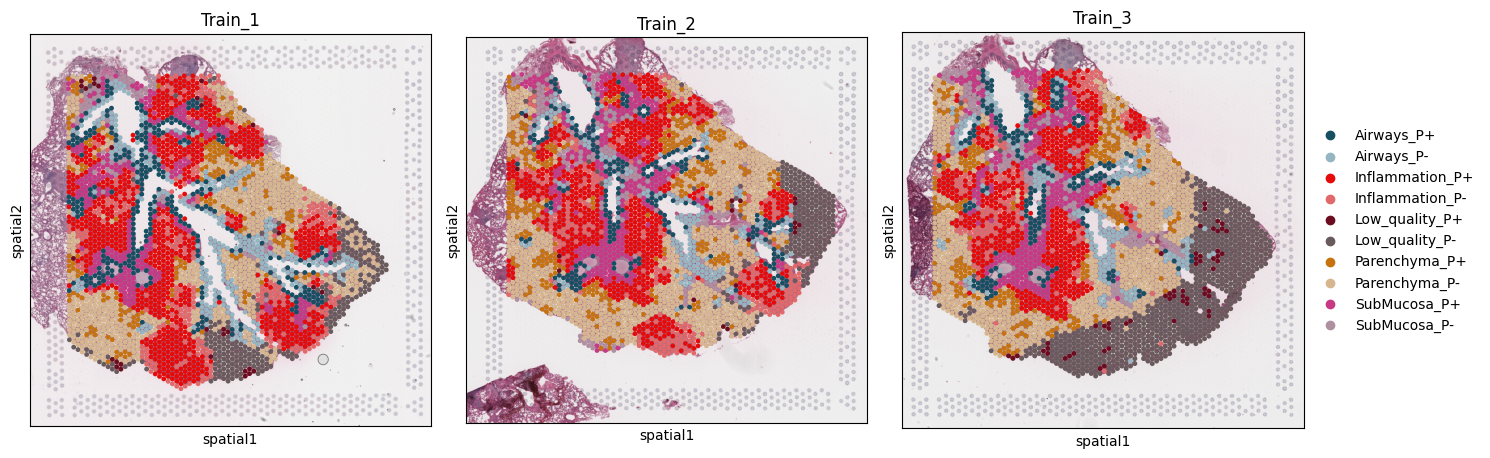

In [ ]:
fig , ax = plt.subplots(1, 3, figsize=(15, 5))
ax = ax.flatten()
palette_dict = {'Parenchyma_P-':"#d6b68e",'Inflammation_P-': "#e16969", 'Low_quality_P-': "#695A5C", 'Airways_P-':"#95b5c0",'SubMucosa_P-':'#af90a1',
				'Parenchyma_P+':"#c6730e",'Inflammation_P+': '#e60b0b', 'Low_quality_P+': '#6c0d1f', 'Airways_P+':"#164e62",'SubMucosa_P+':"#C73985"}


result_sub.obs['bc'] = result_sub.obs['bc'].astype('category')
result_sub.uns['bc_colors'] = [palette_dict[cat] for cat in result_sub.obs['bc'].cat.categories]

for i,key in enumerate(['Train_1', 'Train_2', 'Train_3']):

	#sc.pl.spatial(spdata[key]['dataXNorm'], color='integrated_cluster', ax=ax[i], show=False, size=1.5,title=key, palette=cluster_colors)
	sq.pl.spatial_scatter(result_sub, color='bc',library_id=key,library_key='batch', ax=ax[i],title=key,size=1.5)
	if i!=2:
		ax[i].get_legend().remove()
plt.tight_layout()

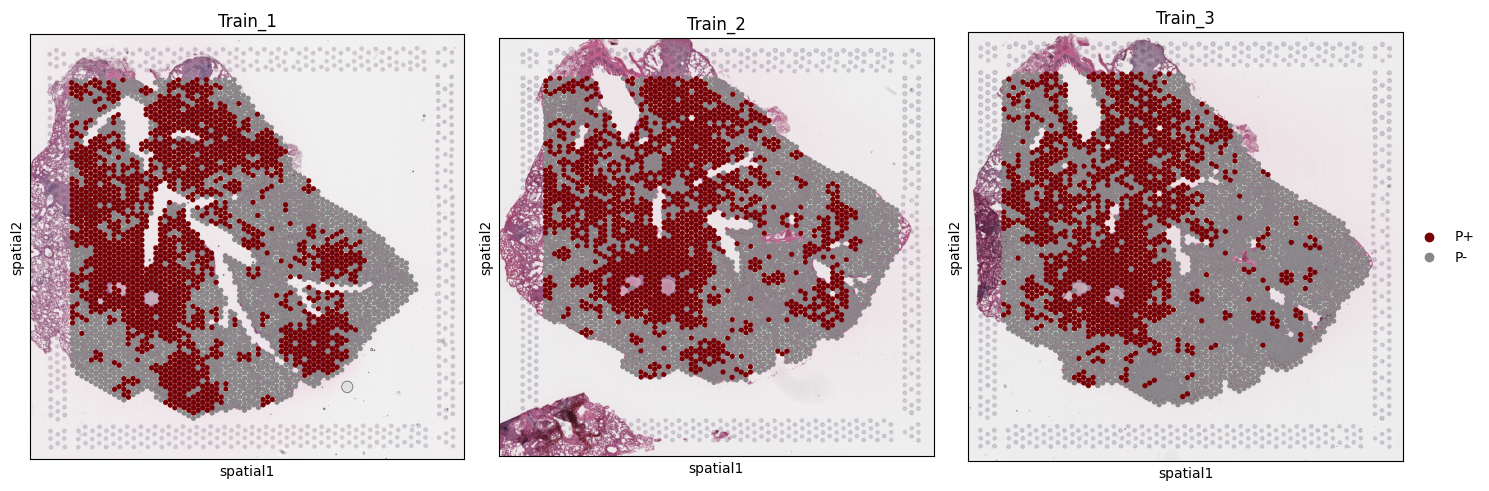

In [ ]:
color=['#aa0000','#888888']

fig , ax = plt.subplots(1, 3, figsize=(15, 5))
ax = ax.flatten()
palette_dict = {'P+':"#770000",'P-':'#888888'}


result_sub.obs['bacterial_labels'] = result_sub.obs['bacterial_labels'].astype('category')
result_sub.uns['bacterial_labels_colors'] = [palette_dict[cat] for cat in result_sub.obs['bacterial_labels'].cat.categories]

for i,key in enumerate(['Train_1', 'Train_2', 'Train_3']):

	#sc.pl.spatial(spdata[key]['dataXNorm'], color='integrated_cluster', ax=ax[i], show=False, size=1.5,title=key, palette=cluster_colors)
	sq.pl.spatial_scatter(result_sub, color='bacterial_labels',library_id=key,library_key='batch', ax=ax[i],title=key,size=1.5)
	if i!=2:
		ax[i].get_legend().remove()
plt.tight_layout()

/beegfs/scratch/ric.cirillo/dimarco.federico/PHD_gnn/INTERACTION/GT-long-range-niches/src/InterScale/evaluation/net_streams.py:433: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_to_wins = adata.obs.groupby(sample_key)[window_key].unique()


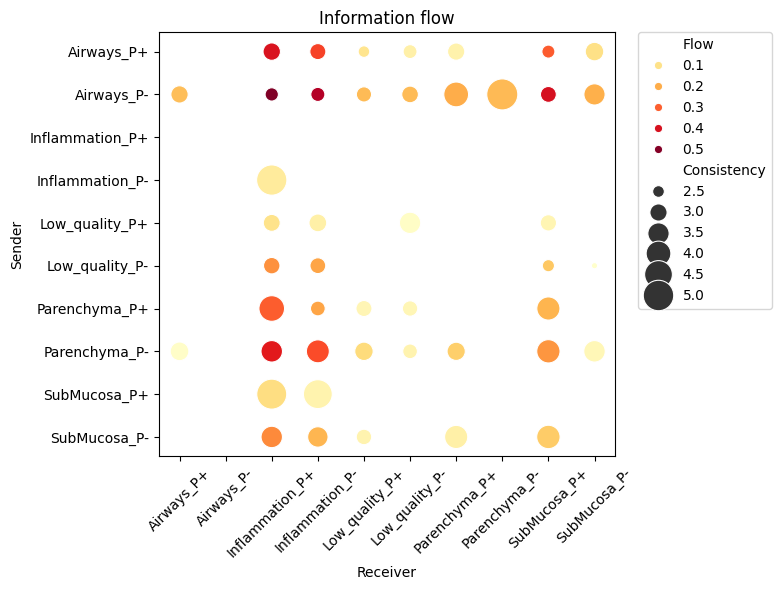

In [ ]:
res=compute_hierarchical_net_flow(result_sub,sample_key='sliding_window_assignment',cell_type_col='bc',compute_net=True)
plot_global_directionality(res['all_samples']['mean'], res['all_samples']['std'], only_positive=True, title="Information flow",figsize=(8, 6))

0.24812082411300643


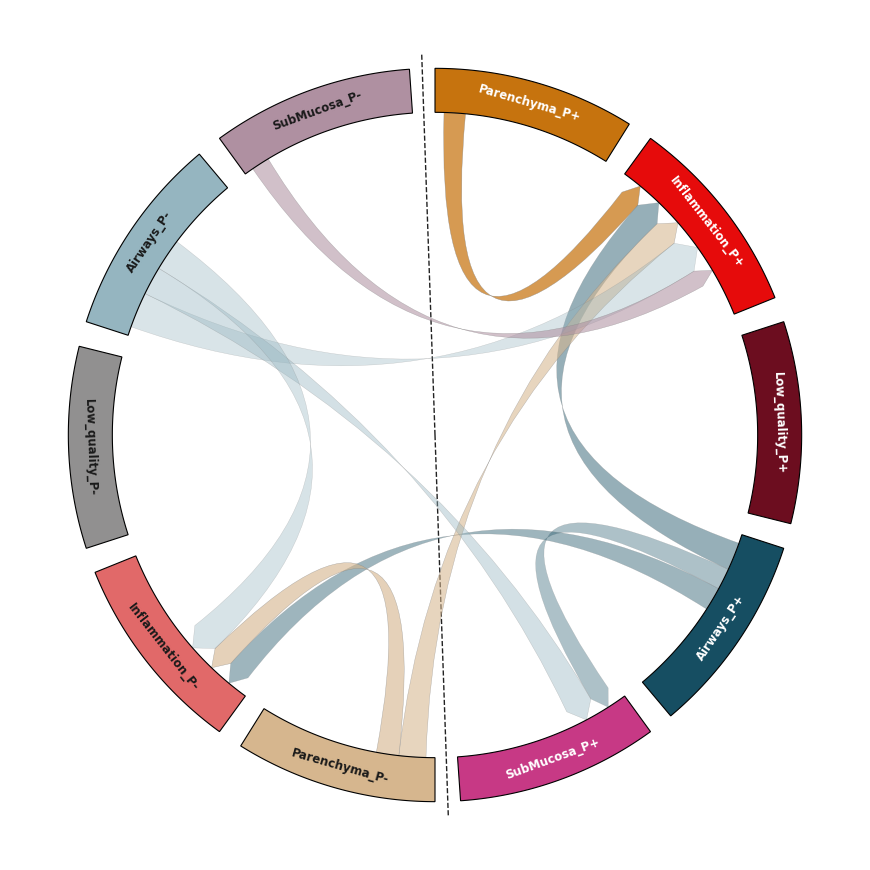

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pycirclize import Circos


sectors_order = [
	"Parenchyma_P+",
	"Inflammation_P+",
	"Low_quality_P+",
	"Airways_P+",
	"SubMucosa_P+",
	"Parenchyma_P-",
	"Inflammation_P-",
	"Low_quality_P-",
	"Airways_P-",
	"SubMucosa_P-"
]



m_net_matrix = res['all_samples']['mean']

flow_df = pd.DataFrame(m_net_matrix, index=sectors_order, columns=sectors_order)
flow_std_df = pd.DataFrame(res['all_samples']['std'], index=sectors_order, columns=sectors_order)
np.fill_diagonal(flow_std_df.values, np.nan)
eps = 1e-6
consistency_df = 1.0 / (flow_std_df + eps)
consistency_df = consistency_df.fillna(np.nanmin(consistency_df.values))
flow_df[flow_df < 0] = 0 


c_min, c_max = consistency_df.values.min(), consistency_df.values.max()
norm_consistency = (consistency_df - c_min) / (c_max - c_min + eps)
alpha_df = 0.25 + 0.70 * norm_consistency  


threshold_mean = np.quantile(flow_df.values,0.9)  
flow_df[flow_df < threshold_mean] = 0.0
print(threshold_mean)



out_sums = flow_df.sum(axis=1)
in_sums = flow_df.sum(axis=0)
total_sector_size = out_sums + in_sums
SECTOR_FIXED_SIZE = 100.0
sector_sizes = {s: SECTOR_FIXED_SIZE for s in sectors_order}

color_map = {'Parenchyma_P-':"#d6b68e",'Inflammation_P-': "#e16969", 'Low_quality_P-': "#919090", 'Airways_P-':"#95b5c0",'SubMucosa_P-':'#af90a1',
				'Parenchyma_P+':"#c6730e",'Inflammation_P+': '#e60b0b', 'Low_quality_P+': '#6c0d1f', 'Airways_P+':"#164e62",'SubMucosa_P+':"#C73985"}


circos = Circos(sector_sizes, space=4)


r_inner, r_outer = 88, 100
r_center = (r_inner + r_outer) / 2  
for sector in circos.sectors:
	track = sector.add_track((r_inner,r_outer))
	track.axis(fc=color_map[sector.name], ec="black", lw=0.8)
	text_color = "white" if "+" in sector.name else "#1a1a1a"

	track.text(
			sector.name,
			x=sector.size / 2,
			r=r_center,
			orientation="horizontal",
			size=8.5,
			weight="bold",
			color=text_color,
			va="center",
			ha="center"
		)



max_flow = flow_df.values.max()
if max_flow == 0:
	max_flow = 1.0
	
raw_widths = pd.DataFrame(0.0, index=sectors_order, columns=sectors_order)
for s in sectors_order:
	for r in sectors_order:
		val = float(flow_df.loc[s, r])
		if val > 0:
			raw_widths.loc[s, r] = (val / max_flow) * 20.0  


required_per_sector = {
	s: float(raw_widths.loc[s].sum() + raw_widths[s].sum())
	for s in sectors_order
}


scaling_factor = {
	s: (90.0 / required_per_sector[s]) if required_per_sector[s] > 90.0 else 1.0
	for s in sectors_order
}
current_offsets = {s: 5.0 for s in sectors_order}  

for sender in sectors_order:
	for receiver in sectors_order:
		val = float(flow_df.loc[sender, receiver])
		if val > 0:
			w_raw = raw_widths.loc[sender, receiver]
			

			w_sender = w_raw * scaling_factor[sender]
			w_receiver = w_raw * scaling_factor[receiver]

			s_start = current_offsets[sender]
			s_end = s_start + w_sender
			current_offsets[sender] = s_end

			r_start = current_offsets[receiver]
			r_end = r_start + w_receiver
			current_offsets[receiver] = r_end

			circos.link(
				(sender, s_start, s_end),
				(receiver, r_start, r_end),
				direction=1,
				color=color_map[sender],
				alpha=float(alpha_df.loc[sender, receiver]),
				ec="grey",
				lw=0.3,
			)


fig = circos.plotfig()

ax = fig.axes[0]


deg_split_bottom = (circos.get_sector("SubMucosa_P+").deg_lim[1] + circos.get_sector("Parenchyma_P-").deg_lim[0]) / 2.0
theta_bottom = np.deg2rad(deg_split_bottom)


theta_top = theta_bottom + np.pi

r_edge = 104  

ax.plot([theta_bottom, theta_bottom], [0, r_edge], color="#222222", linestyle="--", linewidth=1.0, zorder=0)
ax.plot([theta_top, theta_top], [0, r_edge], color="#222222", linestyle="--", linewidth=1.0, zorder=0)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np, pandas as pd
from statsmodels.stats.multitest import multipletests

wk = 'sliding_window_assignment'
obs_df = result_sub.obs
cell_types = sorted(obs_df['bc'].unique())        
ct_index = {c: i for i, c in enumerate(cell_types)}
K = len(cell_types)
B = 1000


W = []
for w in obs_df[wk].unique():
    sub = result_sub[obs_df[wk] == w]
    n = sub.n_obs
    A = np.asarray(sub.obsm['_attn_matrix'])[:, :n].astype(np.float32)
    clus = sub.obs['leiden_cluster'].astype(str).values
    path = sub.obs['bacterial_labels'].astype(str).values
    groups = [np.where(clus == c)[0] for c in np.unique(clus)]
    W.append(dict(A=A, clus=clus, path=path, groups=groups,
                  sec=str(sub.obs['batch'].iloc[0])))

sections = {}
for i, w in enumerate(W):
    sections.setdefault(w['sec'], []).append(i)


def net_window(A, code):
    n = len(code)
    Z = np.zeros((n, K), dtype=np.float32); Z[np.arange(n), code] = 1
    cnt = Z.sum(0)
    S = Z.T @ A @ Z
    d = np.outer(cnt, cnt)
    M = np.divide(S, d, out=np.zeros_like(S), where=d > 0)
    Mn = M.T - M
    m = np.abs(Mn).max()
    return Mn / m if m > 0 else Mn

def codes_for(clus, path):
    return np.array([ct_index[f"{c}_{p}"] for c, p in zip(clus, path)])

def aggregate(path_list):
    return np.nanmean([net_window(w['A'], codes_for(w['clus'], p))
                       for w, p in zip(W, path_list)], axis=0)

def perm_within_cluster(rng):
    out = []
    for w in W:
        p = w['path'].copy()
        for idx in w['groups']:
            p[idx] = rng.permutation(p[idx])
        out.append(p)
    return out

def perm_global(rng):
    out = [None] * len(W)
    for sec, ids in sections.items():
        cat = rng.permutation(np.concatenate([W[i]['path'] for i in ids]))
        pos = 0
        for i in ids:
            n = len(W[i]['path']); out[i] = cat[pos:pos + n]; pos += n
    return out


obs = aggregate([w['path'] for w in W])
ref = res['all_samples']['mean'].loc[cell_types, cell_types].values


def run_null(perm_fn, seed=0):
    rng = np.random.default_rng(seed)
    null = np.empty((B, K, K), dtype=np.float32)
    for b in range(B):
        null[b] = aggregate(perm_fn(rng))
    return null

def summarize(null):
    mu, sd = null.mean(0), null.std(0)
    z = (obs - mu) / np.where(sd > 0, sd, np.nan)
    p_up = (1 + (null >= obs).sum(0)) / (B + 1)
    off = ~np.eye(K, dtype=bool)
    padj = np.ones((K, K))
    padj[off] = multipletests(p_up[off], method="fdr_bh")[1]
    return mu, z, p_up, padj

null_cl = run_null(perm_within_cluster)
null_gl = run_null(perm_global)
mu_cl, z_cl, p_cl, padj_cl = summarize(null_cl)
mu_gl, z_gl, p_gl, padj_gl = summarize(null_gl)

res_df = pd.DataFrame({
    "sender": np.repeat(cell_types, K), "receiver": np.tile(cell_types, K),
    "obs": obs.ravel(),
    "null_cl": mu_cl.ravel(), "z_cl": z_cl.ravel(), "padj_cl": padj_cl.ravel(),
    "null_gl": mu_gl.ravel(), "z_gl": z_gl.ravel(), "padj_gl": padj_gl.ravel(),
})
res_df = res_df[res_df.sender != res_df.receiver]

shown = [(s, r) for s in flow_df.index for r in flow_df.columns if flow_df.loc[s, r] > 0]
res_df.set_index(["sender", "receiver"]).loc[shown].sort_values("padj_cl").round(3)

obs  null_cl   z_cl  padj_cl  null_gl   z_gl  \
sender        receiver                                                          
Airways_P-    SubMucosa_P+     0.402    0.270  3.501    0.018    0.263  3.174   
SubMucosa_P-  Inflammation_P+  0.257    0.144  4.164    0.018    0.169  2.791   
Airways_P-    Inflammation_P+  0.504    0.428  2.543    0.056    0.434  2.380   
Airways_P+    SubMucosa_P+     0.303    0.252  1.301    0.339    0.261  0.953   
Parenchyma_P- Inflammation_P+  0.381    0.360  1.014    0.450    0.354  0.912   
Airways_P-    Inflammation_P-  0.451    0.424  0.732    0.617    0.436  0.521   
Parenchyma_P+ Inflammation_P+  0.302    0.335 -1.173    1.000    0.357 -1.799   
Airways_P+    Inflammation_P+  0.395    0.431 -1.324    1.000    0.430 -1.158   
              Inflammation_P-  0.332    0.425 -2.797    1.000    0.432 -3.368   
Parenchyma_P- Inflammation_P-  0.318    0.353 -1.106    1.000    0.355 -1.185   

                               padj_gl  
sender        receiver                  
Airways_P-    SubMucosa_P+       0.026  
SubMucosa_P-  Inflammation_P+    0.025  
Airways_P-    Inflammation_P+    0.035  
Airways_P+    SubMucosa_P+       0.447  
Parenchyma_P- Inflammation_P+    0.447  
Airways_P-    Inflammation_P-    0.677  
Parenchyma_P+ Inflammation_P+    1.000  
Airways_P+    Inflammation_P+    1.000  
              Inflammation_P-    1.000  
Parenchyma_P- Inflammation_P-    1.000

## Flows

In [ ]:
from interscale.evaluation.net_streams import plot_all_spatial_net_streams
from interscale.evaluation.net_streams import cluster_spatial_flows
from interscale.evaluation.net_streams import plot_flow_clusters
from interscale.evaluation.net_streams import map_clusters_to_cells

In [ ]:
from sklearn.cluster import KMeans

pred=result.obs['bacteria'].values


n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=0)
kmeans_labels = kmeans.fit_predict(pred.reshape(-1,1))

means = [pred[kmeans_labels == i].mean() if np.any(kmeans_labels == i) else -np.inf for i in range(n_clusters)]
order = np.argsort(means)
mapping = {old: new for new, old in enumerate(order)}
kmeans_labels_ordered = np.array([mapping[l] for l in kmeans_labels])


In [ ]:
result.obs['bacterial_labels']=kmeans_labels_ordered


result.obs['bacterial_labels']=result.obs['bacterial_labels'].map({0:'P-',1:'P-',2:'P+'})

result.obs['bacterial_labels']=result.obs['bacterial_labels'].astype('category')

In [ ]:
streams,X_lin,Y_lin = plot_all_spatial_net_streams(result,fov_id='Train_1',fov_key='batch',
							 window_key='sliding_window_assignment',
							 k_dist=0.06,density=1.5,size=1.5,
	cell_type_col='bacterial_labels',alpha=0.5, return_streams=True) 

In [ ]:
from scipy.ndimage import gaussian_filter

sigma_smooth = 1.5 
U_dict = {cat: gaussian_filter(v[0], sigma=sigma_smooth) for cat, v in streams.items()}
V_dict = {cat: gaussian_filter(v[1], sigma=sigma_smooth) for cat, v in streams.items()}
a,b=cluster_spatial_flows(U_dict , V_dict, n_clusters=5)



In [ ]:
result.uns['bacterial_labels_colors']=['#888888','#aa0000']

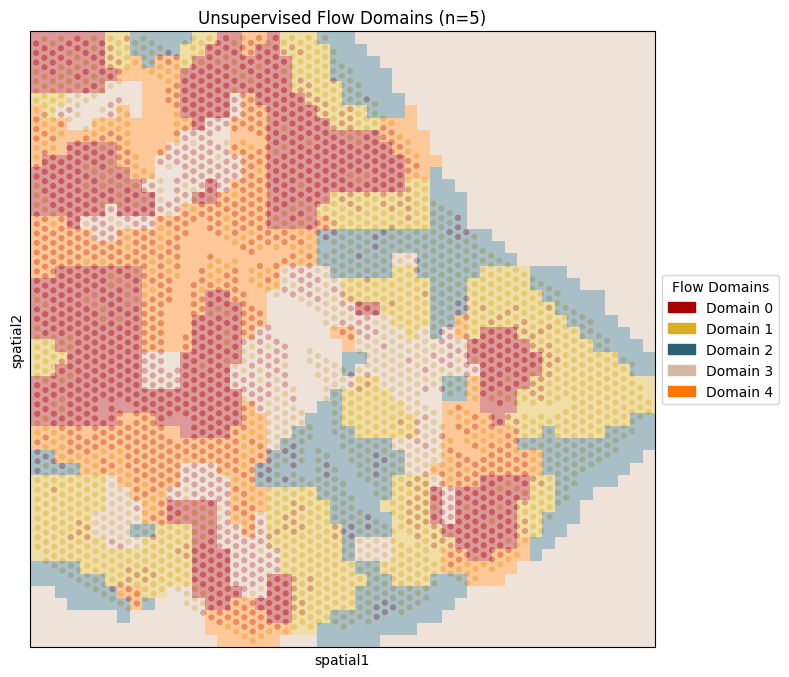

In [ ]:

import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
cluster_grid=a
fov_id='Train_1'
fov_key='batch'
cell_type_col='bacterial_labels'
unique_clusters = np.unique(a)
n_clusters = len(unique_clusters)



palette= {'Domain_0':'#aa0000','Domain_1':"#DBAD24",'Domain_2':"#2a6075",'Domain_3':"#d6b8a2",'Domain_4':"#FD7600"}

color_list = list(palette.values())

# Create the discrete colormap
cmap= ListedColormap(color_list, name="Domains")

fig, ax = plt.subplots(figsize=(10, 8))
# Overlay the original cell positions
sq.pl.spatial_scatter(
	result, color=cell_type_col, 
	library_key=fov_key, library_id=[fov_id],
	ax=ax, spatial_key='spatial', 
	alpha=0.4, img=False, 
	title=f"Unsupervised Flow Domains (n={len(np.unique(cluster_grid))})"
)
# Plot the clusters as a heatmap (Voronoi-like segmentation of flow)
im = ax.pcolormesh(X_lin, Y_lin, cluster_grid, 
				cmap=cmap, alpha=0.4, shading='auto',
				vmin=unique_clusters.min()-0.5, 
				vmax=unique_clusters.max()+0.5)

legend_handles = []
for i, cluster_id in enumerate(unique_clusters):
	color = cmap(i)
	patch = mpatches.Patch(color=color, label=f"Domain {int(cluster_id)}")
	legend_handles.append(patch)


ax.legend(handles=legend_handles, title="Flow Domains", 
		loc='center left', bbox_to_anchor=(1, 0.5))

In [ ]:
c=map_clusters_to_cells(a, X_lin, Y_lin, result, fov_id='Train_1', fov_key='batch')

In [ ]:
dummy=result[result.obs['batch']=='Train_1'].copy()

In [ ]:
dummy.obs['flow_cluster'] = c
dummy.obs['flow_cluster'].value_counts()

flow_cluster
Domain_0    901
Domain_1    757
Domain_4    641
Domain_3    476
Domain_2    437
Name: count, dtype: int64

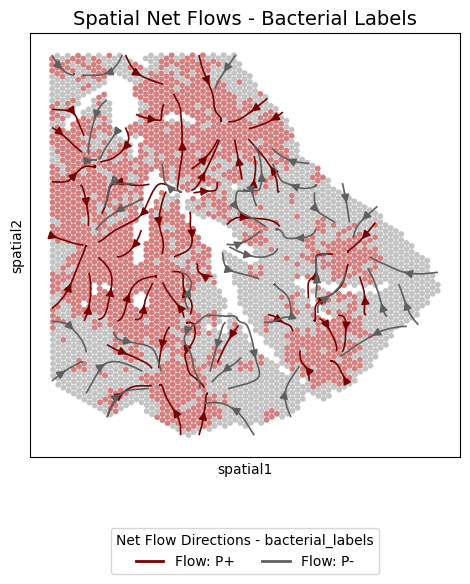

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(10, 6))
plot_all_spatial_net_streams(dummy,fov_id='Train_1',fov_key='batch',
							 window_key='sliding_window_assignment',
							 k_dist=0.06,density=0.75,size=1.5,ax=ax,legend_loc='best',
	cell_type_col='bacterial_labels',alpha=0.5)

ax.set_title('Spatial Net Flows - Bacterial Labels', fontsize=14)
plt.tight_layout()

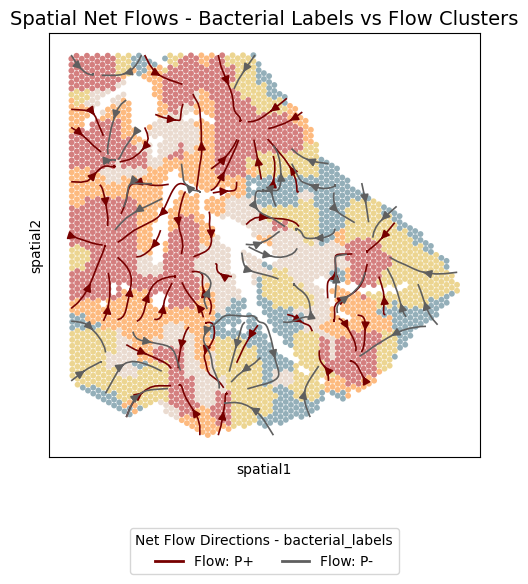

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(10, 6))
ax.set_clip_on(False)
dummy.uns['bacterial_labels_colors']=['#aa0000','#888888']

dummy.uns['flow_cluster_colors']=['#aa0000',"#DBAD24","#2a6075","#d6b8a2","#FD7600"]

plot_all_spatial_net_streams(dummy,fov_id='Train_1',fov_key='batch',
							 window_key='sliding_window_assignment',
							 k_dist=0.06,density=0.75,size=1.5,ax=ax,legend_loc='best',
	cell_type_col='bacterial_labels',alpha=0.5,additional_embeddings='flow_cluster')

ax.set_title('Spatial Net Flows - Bacterial Labels vs Flow Clusters', fontsize=14)
plt.tight_layout()


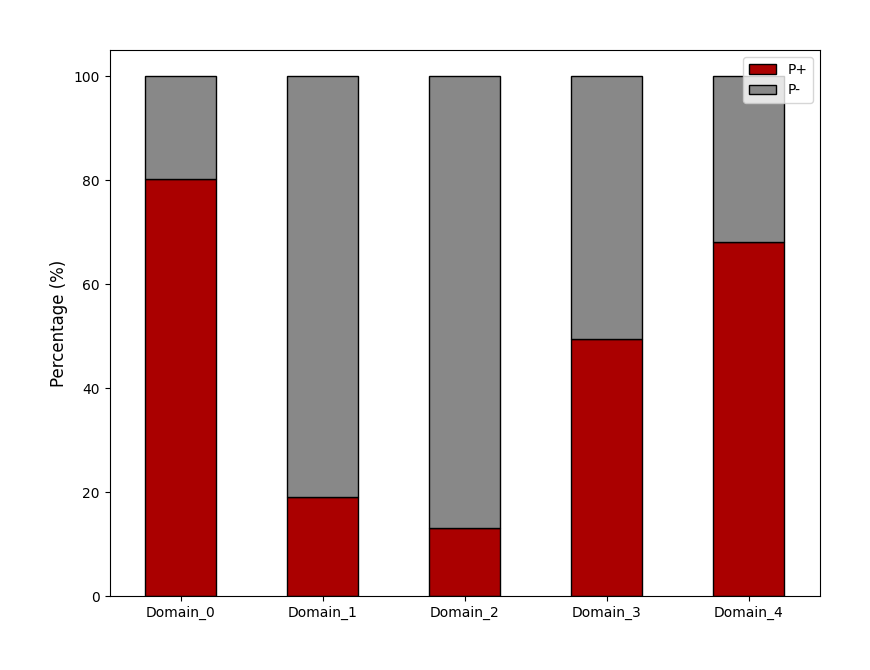

In [ ]:
import matplotlib.ticker as mtick
crosstab_pct = (
    pd.crosstab(dummy.obs["flow_cluster"], dummy.obs["bacterial_labels"], normalize="index") * 100
)
ax = crosstab_pct.plot(
    kind="bar",
    stacked=True,
    #hue='bacterial_labels',,
	color=['#aa0000','#888888'],
    figsize=(8, 6),
    edgecolor="black",
    linewidth=1,
)

plt.xlabel("", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.legend(title="", title_fontsize=12, fontsize=10)
plt.xticks(rotation=0)

plt.tight_layout()

In [ ]:
dummy.save('Data/dummy1.h5ad')

## Host clusters vs Domains

Text(0.5, 1.0, 'Leiden to Flow Cluster Mapping')

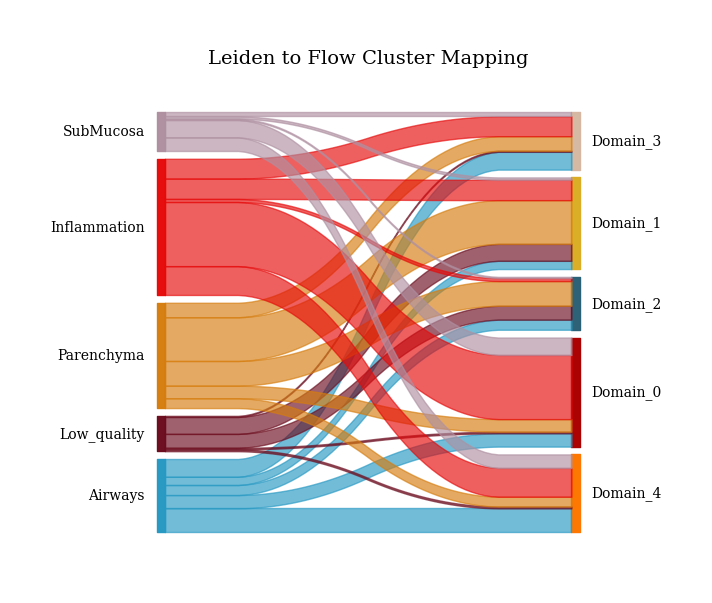

In [ ]:
import matplotlib.pyplot as plt
from pySankey.sankey import sankey


df = dummy.obs[["leiden_cluster", "flow_cluster"]].copy()


colors_source = {
    "Parenchyma": "#d67d0f",
    "Inflammation": "#e60b0b",
    "Low_quality": "#6c0d1f",
    "Airways": "#2799c3",
    "SubMucosa": "#af90a1",
}

colors_target = {
    "Domain_0": "#aa0000",
    "Domain_1": "#DBAD24",
    "Domain_2": "#2a6075",
    "Domain_3": "#d6b8a2",
    "Domain_4": "#FD7600",
}


color_dict = {**colors_source, **colors_target}



sankey(
    left=df["leiden_cluster"],
    right=df["flow_cluster"],
    colorDict=color_dict,
    fontsize=10,
    aspect=1,
)

plt.title("Leiden to Flow Cluster Mapping", fontsize=14, pad=20)

In [ ]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

# Cast to strings to ensure consistent categorical representation
labels_true = dummy.obs["leiden_cluster"].astype(str)
labels_pred = dummy.obs["flow_cluster"].astype(str)

ari = adjusted_rand_score(labels_true, labels_pred)
ami = adjusted_mutual_info_score(labels_true, labels_pred)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Adjusted Mutual Information (AMI): {ami:.4f}")

Adjusted Rand Index (ARI): 0.1056
Adjusted Mutual Information (AMI): 0.1273


## Domains spatial autocorrelation

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix


coords = dummy.obsm["spatial"]
labels = dummy.obs["flow_cluster"].to_numpy()
categories = np.unique(labels)
n_samples = len(labels)
k = 6
n_perms = 999


tree = cKDTree(coords)
_, indices = tree.query(coords, k=k + 1)
row_idx = np.repeat(np.arange(n_samples), k)
col_idx = indices[:, 1:].flatten()


adj = csr_matrix((np.ones(len(row_idx)), (row_idx, col_idx)), shape=(n_samples, n_samples))
adj = ((adj + adj.T) > 0).astype(np.float64)


def count_bb(binary_vec, adjacency):
    return float(adjacency.dot(binary_vec).dot(binary_vec) / 2.0)


results = []
rng = np.random.default_rng(seed=42)

for cat in categories:
    mask = (labels == cat).astype(np.float64)
    obs_bb = count_bb(mask, adj)
    

    perm_bb = np.zeros(n_perms)
    for i in range(n_perms):
        shuffled_mask = rng.permutation(mask)
        perm_bb[i] = count_bb(shuffled_mask, adj)
        
    mean_null = np.mean(perm_bb)
    std_null = np.std(perm_bb, ddof=1)
    z_score = (obs_bb - mean_null) / std_null if std_null > 0 else 0.0

    p_val = (np.sum(perm_bb >= obs_bb) + 1) / (n_perms + 1)
    
    results.append({
        "category": cat,
        "observed_joins": obs_bb,
        "expected_joins": mean_null,
        "z_score": z_score,
        "p_value": p_val
    })

jc_df = pd.DataFrame(results).sort_values("z_score", ascending=False)
print(jc_df)

   category  observed_joins  expected_joins    z_score  p_value
0  Domain_0          2353.0      790.090090  76.507180    0.001
1  Domain_1          1912.0      557.906907  73.993480    0.001
2  Domain_2          1053.0      186.196196  73.356657    0.001
4  Domain_4          1593.0      398.865866  73.108907    0.001
3  Domain_3          1118.0      220.572573  68.482381    0.001


In [ ]:
res=compute_hierarchical_net_flow(dummy,sample_key='sliding_window_assignment',cell_type_col="flow_cluster",compute_net=True)

In [ ]:
from interscale.evaluation.net_streams import characterize_flow_clusters


adata_slice = dummy.copy()

M_net = res['all_samples']['mean']

net_balance = M_net.sum(axis=0) - M_net.sum(axis=1)


char_df = characterize_flow_clusters(U_dict, V_dict, cluster_grid=a, k=1)


target_cat = [
    c for c in U_dict.keys() if "pos" in str(c).lower() or str(c) == "1"
]
target_cat = target_cat[0] if len(target_cat) > 0 else list(U_dict.keys())[0]

bact_char = (
    char_df[char_df["cell_type"] == target_cat]
    .copy()
    .sort_values("cluster_id")
)
bact_char["flow_domain"] = [f"Domain_{int(i)}" for i in bact_char["cluster_id"]]
bact_char = bact_char.set_index("flow_domain")

# Align indices
common_doms = sorted(list(M_net.index))
eval_df = pd.DataFrame(
    {
        "Net_Information_Balance": net_balance.loc[common_doms],
        "Bacterial_Divergence": bact_char.loc[common_doms, "avg_divergence"],
        "Role": bact_char.loc[common_doms, "role"],
    }
)

from scipy.stats import pearsonr, spearmanr

r_p, _ = pearsonr(
    eval_df["Net_Information_Balance"], eval_df["Bacterial_Divergence"]
)
r_s, _ = spearmanr(
    eval_df["Net_Information_Balance"], eval_df["Bacterial_Divergence"]
)
print(
    f"\nCorrelazione Net Balance vs Divergenza: Pearson={r_p:.3f}, Spearman={r_s:.3f}"
)



In [ ]:

full_char = characterize_flow_clusters(U_dict, V_dict, cluster_grid=a, k=1)
pivoted_div = full_char.pivot(
    index="cluster_id", columns="cell_type", values="avg_divergence"
)
pivoted_div.index = [f"Domain_{int(i)}" for i in pivoted_div.index]


pivoted_div["Mean_Total_Divergence"] = pivoted_div.mean(axis=1)


common_doms = sorted(list(net_balance.index))
eval_df = pd.DataFrame(
    {
        "Net_Information_Balance": net_balance.loc[common_doms],
        "Bacterial_Divergence": pivoted_div.loc[common_doms, target_cat],
        "Host_Divergence": pivoted_div.loc[
            common_doms, [c for c in pivoted_div.columns if c != target_cat][0]
        ],
        "Total_Divergence": pivoted_div.loc[
            common_doms, "Mean_Total_Divergence"
        ],
    }
)


r_s_tot, p_val = spearmanr(
    eval_df["Net_Information_Balance"], eval_df["Total_Divergence"]
)
print(f"Spearman Net vs Total Divergence: {r_s_tot:.3f}")


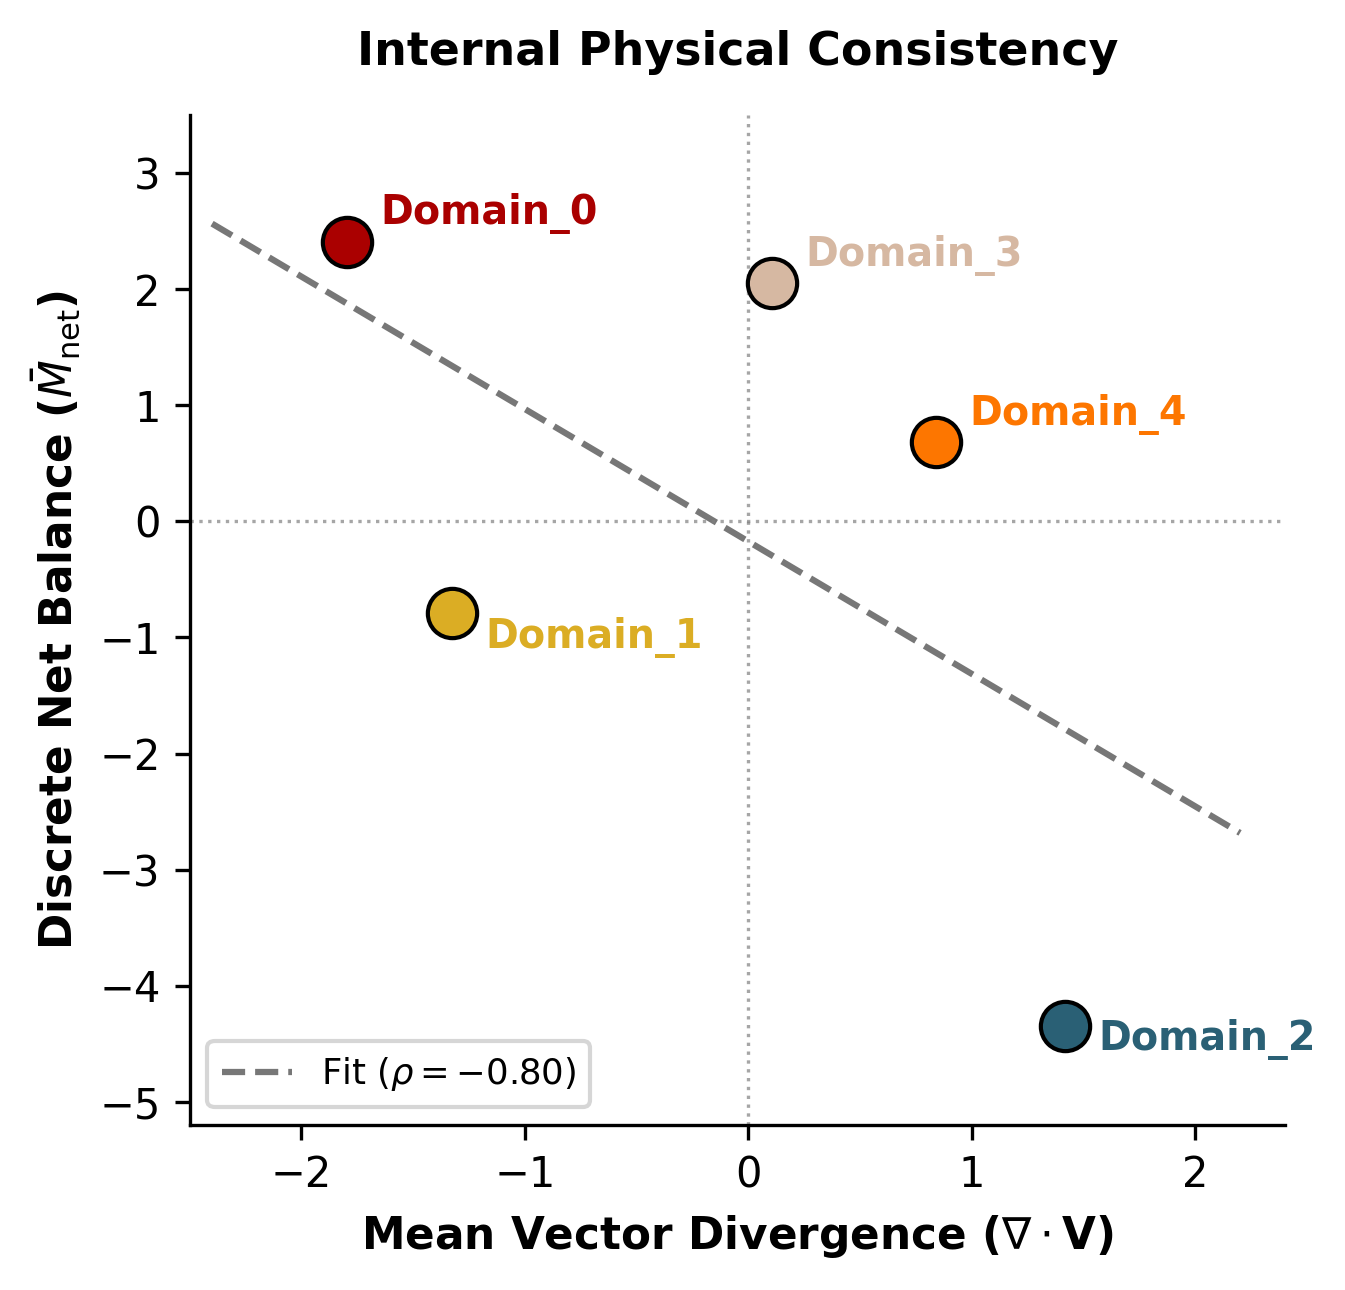

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


data = {
    "Domain": ["Domain_0", "Domain_1", "Domain_2", "Domain_3", "Domain_4"],
    "Net_Balance": [2.41, -0.79, -4.35, 2.05, 0.68],
    "D_pos": [-2.17, -0.27, 0.48, 0.06, 1.30],
    "D_neg": [-1.42, -2.38, 2.35, 0.15, 0.38],
}
df_phys = pd.DataFrame(data)
df_phys["Mean_Divergence"] = (df_phys["D_pos"] + df_phys["D_neg"]) / 2


palette = {'Domain_0':'#aa0000','Domain_1':"#DBAD24",'Domain_2':"#2a6075",'Domain_3':"#d6b8a2",'Domain_4':"#FD7600"}


fig, ax = plt.subplots(figsize=(4.6, 4.4), dpi=300)


fit_subset = df_phys
m, b = np.polyfit(
    fit_subset["Mean_Divergence"], fit_subset["Net_Balance"], deg=1
)
x_vals = np.linspace(-2.4, 2.2, 100)
ax.plot(
    x_vals,
    m * x_vals + b,
    color="#555555",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label=r"Fit ($\rho = -0.80$)",
)


offsets = {
    "Domain_0": (0.15, 0.15),
    "Domain_1": (0.15, -0.3),
    "Domain_2": (0.15, -0.2),
    "Domain_3": (0.15, 0.15),
    "Domain_4": (0.15, 0.15),
}

for _, row in df_phys.iterrows():
    d = row["Domain"]
    ax.scatter(
        row["Mean_Divergence"],
        row["Net_Balance"],
        color=palette[d],
        s=140,
        edgecolors="black",
        linewidth=1.0,
        zorder=5,
    )
    dx, dy = offsets[d]
    ax.annotate(
        d,
        (row["Mean_Divergence"] + dx, row["Net_Balance"] + dy),
        fontsize=9.5,
        fontweight="bold",
        color=palette[d],
    )

# Assi e soglie zero
ax.axhline(0, color="gray", linestyle=":", linewidth=0.8, alpha=0.7)
ax.axvline(0, color="gray", linestyle=":", linewidth=0.8, alpha=0.7)

ax.set_xlabel(
    r"Mean Vector Divergence ($\nabla \cdot \mathbf{V}$)",
    fontsize=10.5,
    fontweight="bold",
)
ax.set_ylabel(
    r"Discrete Net Balance ($\bar{M}_{\mathrm{net}}$)",
    fontsize=10.5,
    fontweight="bold",
)
ax.set_title("Internal Physical Consistency", fontsize=11, fontweight="bold", pad=12)

ax.set_xlim(-2.5, 2.4)
ax.set_ylim(-5.2, 3.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower left", frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()

## Domains interaction

0.18539371110255928


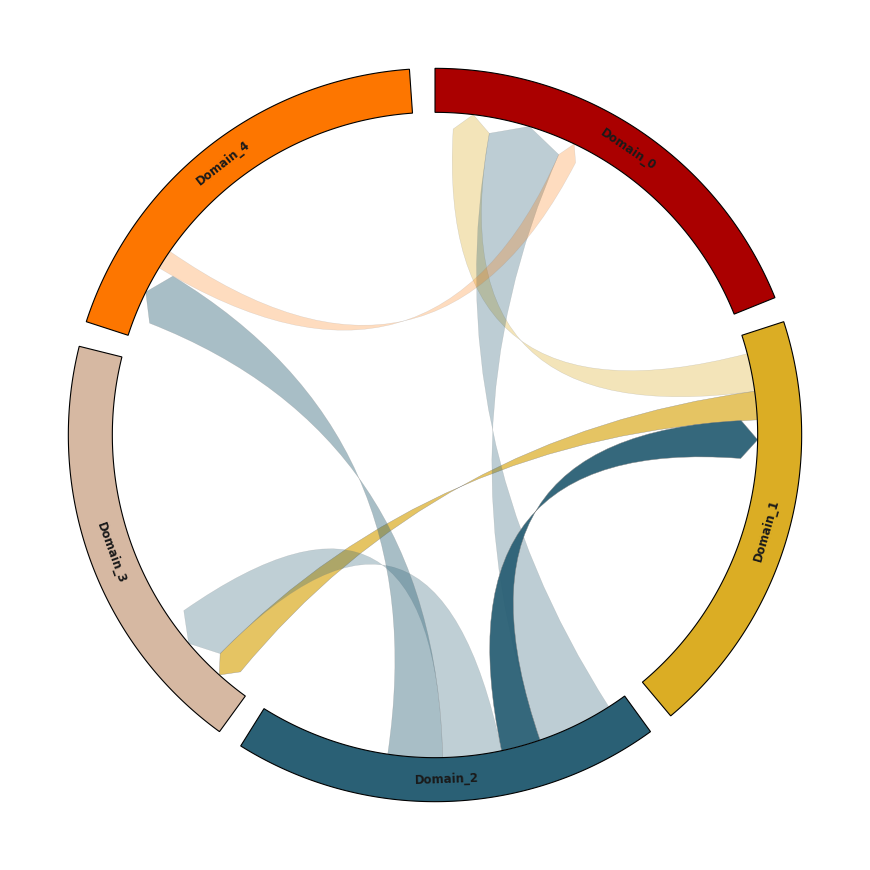

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pycirclize import Circos
['#aa0000',"#DBAD24","#2a6075","#d6b8a2","#FD7600"]

sectors_order = [
	"Domain_0",
	"Domain_1",
	"Domain_2",
	"Domain_3",
	"Domain_4",
]



m_net_matrix = res['all_samples']['mean'].copy()

flow_df = pd.DataFrame(m_net_matrix, index=sectors_order, columns=sectors_order)
flow_std_df = pd.DataFrame(res['all_samples']['std'], index=sectors_order, columns=sectors_order)
np.fill_diagonal(flow_std_df.values, np.nan)
eps = 1e-6
consistency_df = 1.0 / (flow_std_df + eps)
consistency_df = consistency_df.fillna(np.nanmin(consistency_df.values))
flow_df[flow_df < 0] = 0 


c_min, c_max = consistency_df.values.min(), consistency_df.values.max()
norm_consistency = (consistency_df - c_min) / (c_max - c_min + eps)
alpha_df = 0.25 + 0.70 * norm_consistency 


threshold_mean = np.quantile(flow_df.values,0.75)  
flow_df[flow_df < threshold_mean] = 0.0
print(threshold_mean)



out_sums = flow_df.sum(axis=1)
in_sums = flow_df.sum(axis=0)
total_sector_size = out_sums + in_sums
SECTOR_FIXED_SIZE = 100.0
sector_sizes = {s: SECTOR_FIXED_SIZE for s in sectors_order}

color_map = {'Domain_0':'#aa0000','Domain_1':"#DBAD24",'Domain_2':"#2a6075",'Domain_3':"#d6b8a2",'Domain_4':"#FD7600"}


circos = Circos(sector_sizes, space=4)



r_inner, r_outer = 88, 100
r_center = (r_inner + r_outer) / 2  
for sector in circos.sectors:
	track = sector.add_track((r_inner,r_outer))
	track.axis(fc=color_map[sector.name], ec="black", lw=0.8)
	text_color = "white" if "+" in sector.name else "#1a1a1a"
	track.text(
			sector.name,
			x=sector.size / 2,
			r=r_center,
			orientation="horizontal",
			size=8.5,
			weight="bold",
			color=text_color,
			va="center",
			ha="center"
		)



max_flow = flow_df.values.max()
if max_flow == 0:
	max_flow = 1.0
	
raw_widths = pd.DataFrame(0.0, index=sectors_order, columns=sectors_order)
for s in sectors_order:
	for r in sectors_order:
		val = float(flow_df.loc[s, r])
		if val > 0:
			raw_widths.loc[s, r] = (val / max_flow) * 20.0  


required_per_sector = {
	s: float(raw_widths.loc[s].sum() + raw_widths[s].sum())
	for s in sectors_order
}

scaling_factor = {
	s: (90.0 / required_per_sector[s]) if required_per_sector[s] > 90.0 else 1.0
	for s in sectors_order
}
current_offsets = {s: 5.0 for s in sectors_order} 
for sender in sectors_order:
	for receiver in sectors_order:
		val = float(flow_df.loc[sender, receiver])
		if val > 0:
			w_raw = raw_widths.loc[sender, receiver]
			

			w_sender = w_raw * scaling_factor[sender]
			w_receiver = w_raw * scaling_factor[receiver]

			s_start = current_offsets[sender]
			s_end = s_start + w_sender
			current_offsets[sender] = s_end

			r_start = current_offsets[receiver]
			r_end = r_start + w_receiver
			current_offsets[receiver] = r_end

			circos.link(
				(sender, s_start, s_end),
				(receiver, r_start, r_end),
				direction=1,
				color=color_map[sender],
				alpha=float(alpha_df.loc[sender, receiver]),
				ec="grey",
				lw=0.3,
			)


fig = circos.plotfig()


plt.tight_layout()
plt.show()

## Domains markers 

In [ ]:
dummyall=spdata['Train_1']['dataXNorm'].copy()

In [ ]:
dummyall.obs['flow_cluster'] = dummy.obs['flow_cluster'].values

In [ ]:
sc.pp.normalize_total(dummyall, target_sum=1e4)

In [ ]:
sc.tl.rank_genes_groups(dummyall, groupby='flow_cluster', method='wilcoxon', key_added='rank_genes_flow_cluster')

In [ ]:
sc.get.rank_genes_groups_df(dummyall,group=None, pval_cutoff=0.05, key='rank_genes_flow_cluster')

In [ ]:
import gseapy as gp
GO_res=pd.DataFrame()
for i in dummy.obs['flow_cluster'].unique():
	markers=sc.get.rank_genes_groups_df(dummyall, group=i,key='rank_genes_flow_cluster', pval_cutoff=0.05)

	glist=markers[markers['pvals_adj']<0.05]['names'].head(100)

	glist=glist.str.upper()
	pre_res = gp.enrichr(gene_list=glist,
		gene_sets='GO_Biological_Process_2025',
		organism='mouse',
		outdir=None,
		verbose=True)
	
	d=pre_res.res2d
	d['Cluster']=i
	GO_res=pd.concat([GO_res, d], ignore_index=True)
	

2026-10-20 10:44:53,360 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-10-20 10:44:53,950 [INFO] Done.
2026-10-20 10:44:54,540 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-10-20 10:44:55,211 [INFO] Done.
2026-10-20 10:44:55,800 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-10-20 10:44:56,470 [INFO] Done.
2026-10-20 10:44:57,058 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-10-20 10:44:57,725 [INFO] Done.
2026-10-20 10:44:58,314 [INFO] Online enrichment analysis with libraries: GO_Biological_Process_2025
2026-10-20 10:44:58,894 [INFO] Done.


In [ ]:
GO_res[(GO_res['Adjusted P-value']<0.05)].to_excel('Results/GO_Enrichment_FDomains_allgenes.xlsx', index=False)

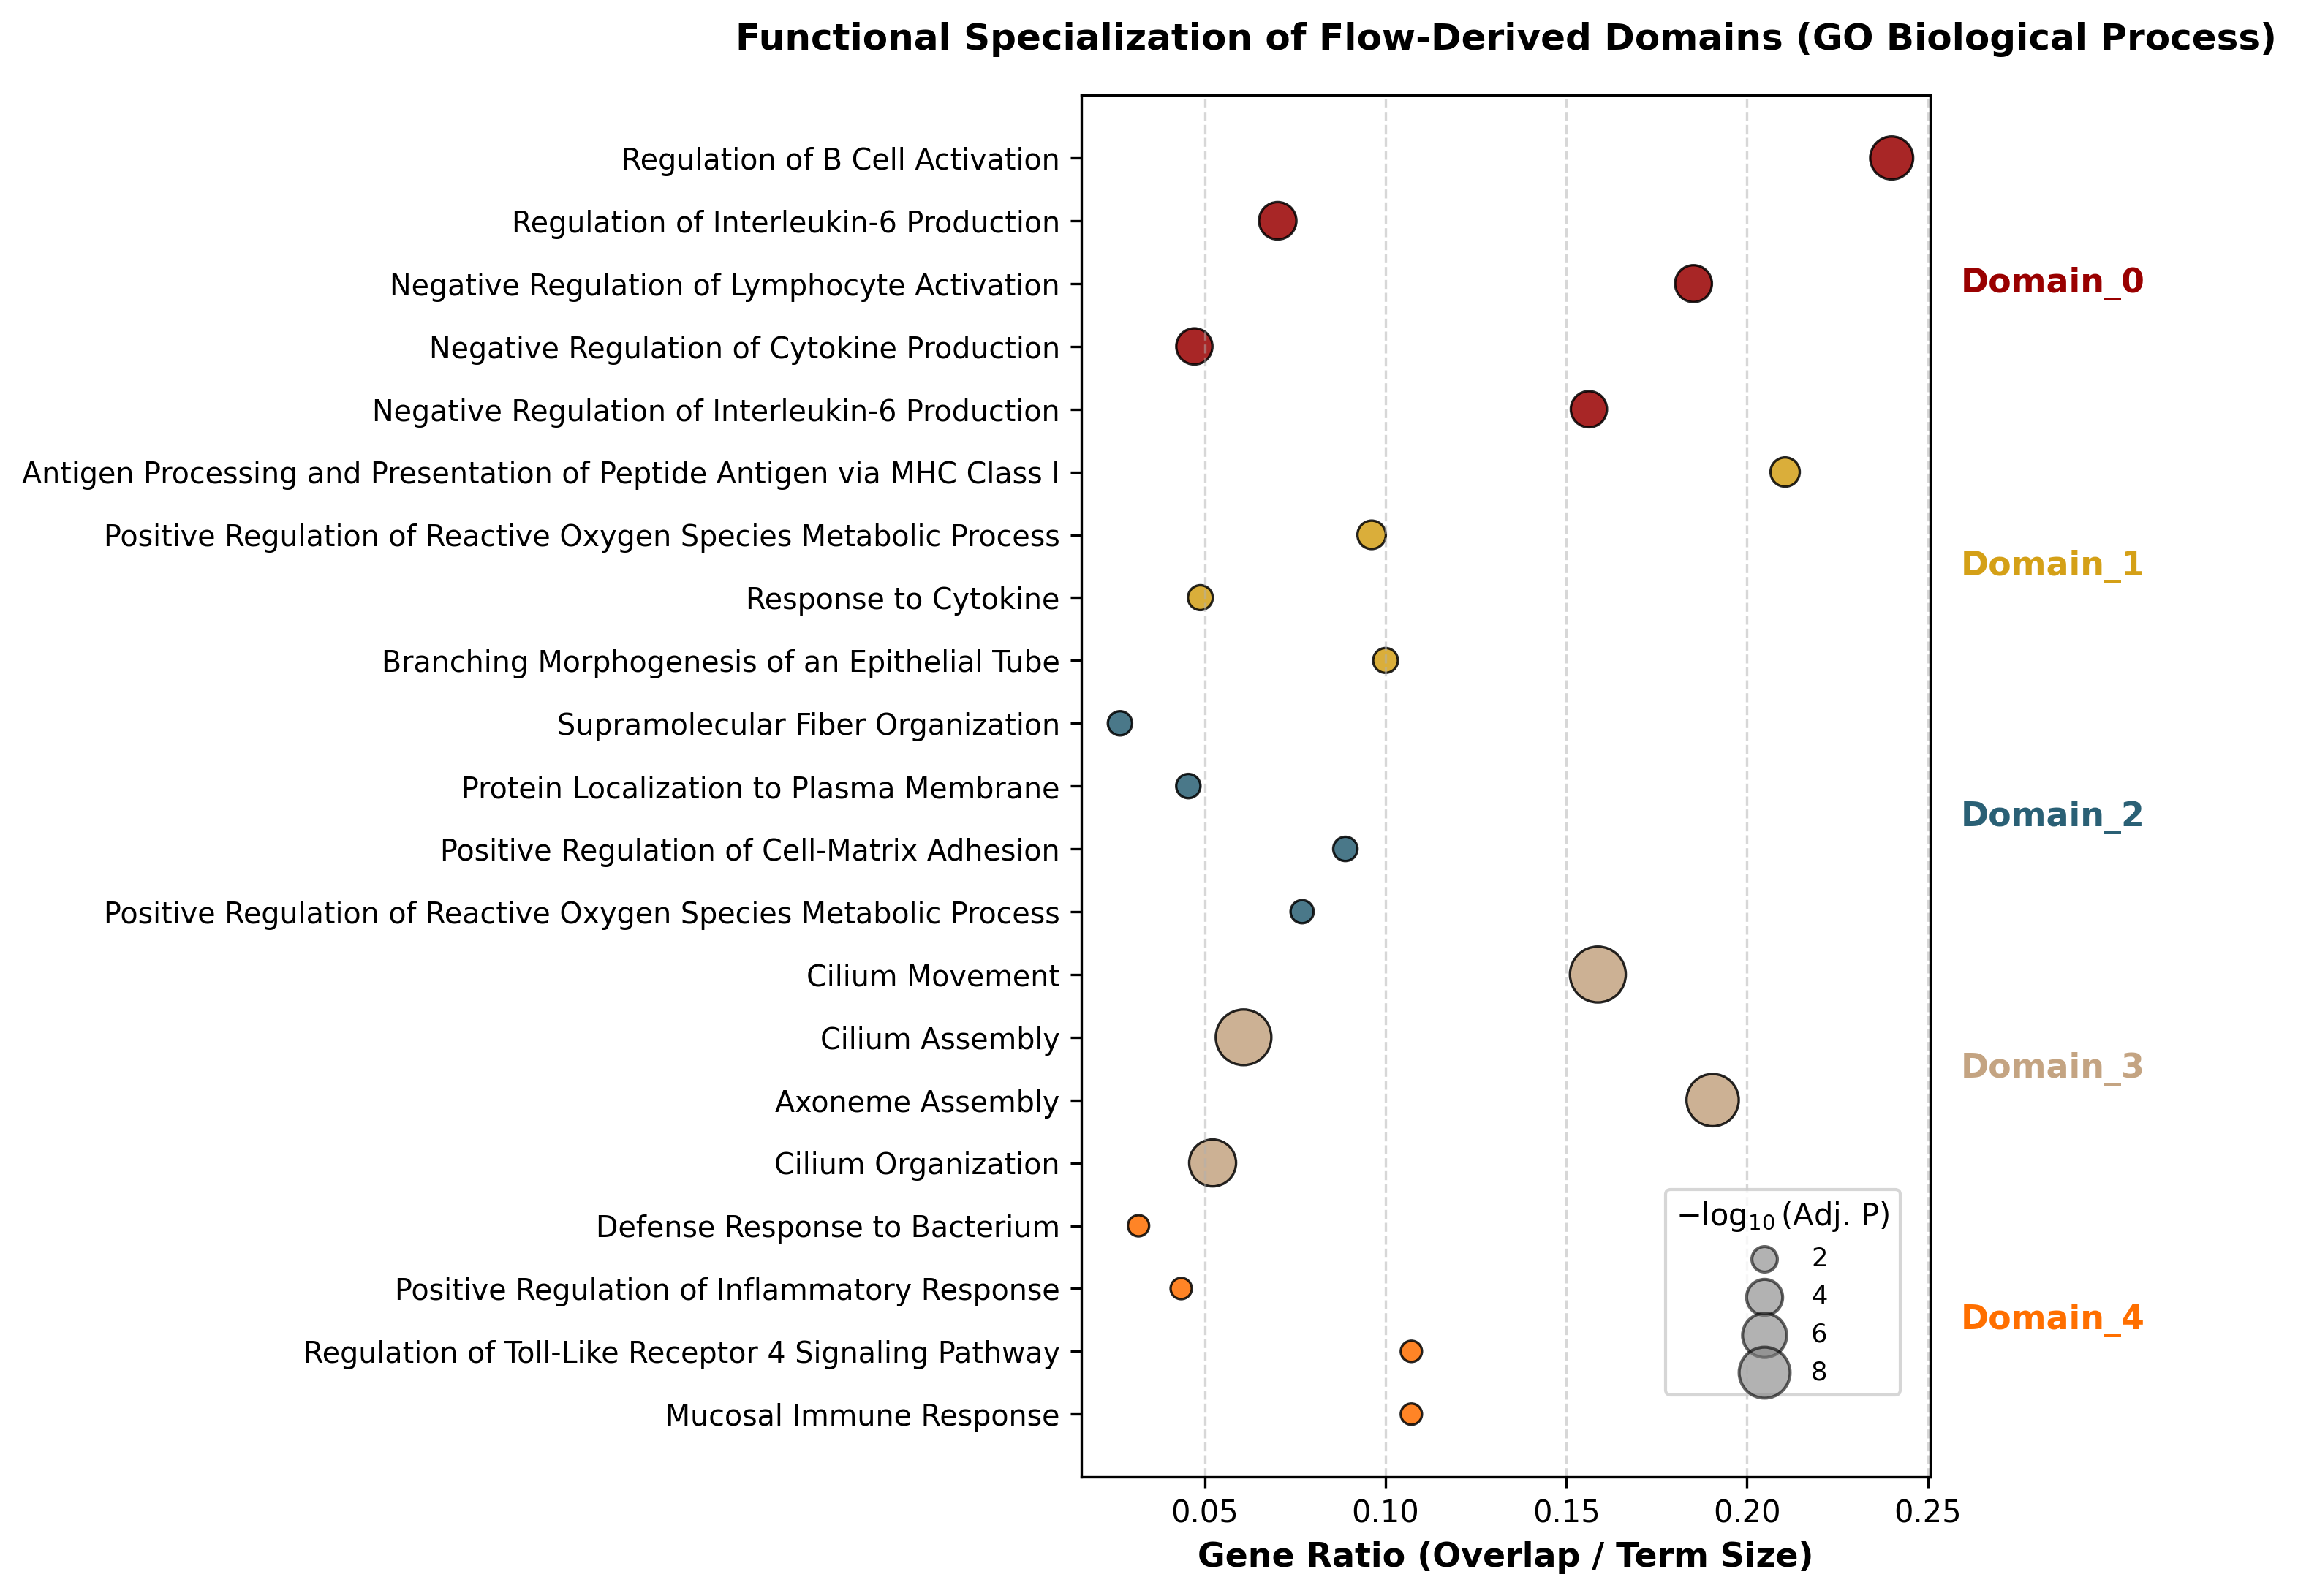

In [ ]:
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


filepath = "Results/GO_Enrichment_FDomains_allgenes.xlsx"
df = pd.read_excel(filepath)


def dedup_top(sub, n, jacc=0.8):
    sub = sub.sort_values(["Adjusted P-value", "P-value"])
    keep, sets = [], []
    for i, r in sub.iterrows():
        g = set(str(r["Genes"]).split(";"))
        if all(len(g & s) / len(g | s) < jacc for s in sets):
            keep.append(i); sets.append(g)
        if len(keep) == n:
            break
    return sub.loc[keep].copy()

n_terms = {"Domain_0": 5, "Domain_1": 4, "Domain_2": 4, "Domain_3": 4, "Domain_4": 5}
order = ["Domain_0", "Domain_1", "Domain_2", "Domain_3", "Domain_4"] 
parts = [dedup_top(df[df["Cluster"] == c], n_terms[c]) for c in order]
plot_data = pd.concat(parts, ignore_index=True)

palette = {
    "Domain_0": "#990000",
    "Domain_1": "#D4A017",
    "Domain_2": "#2a6075",
    "Domain_3": "#C4A482",
    "Domain_4": "#FF6F00",
}


plot_data["GeneRatio"] = plot_data["Overlap"].apply(lambda x: eval(str(x)))


plot_data["neg_log10_adj_p"] = -np.log10(plot_data["Adjusted P-value"])


plot_data["Clean_Term"] = plot_data["Term"].apply(
    lambda x: re.sub(r"\s*\(GO:\d+\)", "", str(x))
)

plot_data = plot_data.iloc[::-1].reset_index(drop=True)



fig, ax = plt.subplots(figsize=(9, 7.5), dpi=300)

y_positions = np.arange(len(plot_data))
point_sizes = plot_data["neg_log10_adj_p"] * 35


ax.scatter(
    plot_data["GeneRatio"],
    y_positions,
    s=point_sizes,
    c=[palette[c] for c in plot_data["Cluster"]],
    alpha=0.85,
    edgecolors="black",
    linewidth=0.8,
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Clean_Term"], fontsize=9.5)
ax.set_xlabel("Gene Ratio (Overlap / Term Size)", fontsize=11, fontweight="bold")
ax.set_title(
    "Functional Specialization of Flow-Derived Domains (GO Biological Process)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
ax.grid(axis="x", linestyle="--", alpha=0.5)


max_x = plot_data["GeneRatio"].max()
for cluster, col in palette.items():
    sub = plot_data[plot_data["Cluster"] == cluster]
    if len(sub) > 0:
        mid_y = (sub.index.min() + sub.index.max()) / 2
        ax.text(
            max_x * 1.08,
            mid_y,
            cluster,
            color=col,
            fontweight="bold",
            fontsize=11,
            va="center",
        )


legend_sizes = [2, 4, 6, 8]
for s in legend_sizes:
    ax.scatter(
        [],
        [],
        s=s * 35,
        c="grey",
        alpha=0.6,
        edgecolors="black",
        label=f"{s}",
    )

ax.legend(
    scatterpoints=1,
    frameon=True,
    title=r"$-\log_{10}(\text{Adj. P})$",
    loc="lower right",
    bbox_to_anchor=(0.98, 0.05),
    fontsize=8.5,
)


plt.subplots_adjust(left=0.42, right=0.85, top=0.92, bottom=0.08)


plt.savefig("INTERACTION/Thesis/Figures/go_enrichment_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()